In [2]:

from pathlib import Path
from google.colab import drive
import pandas as pd
import torch
import shutil
from PIL import Image
from tqdm.auto import tqdm

# 1. Mount Google Drive
PROJECT = Path("/content/drive5/MyDrive/Ocular_Project")

if not (PROJECT / "results").is_dir():
    drive.mount("/content/drive5")

# Verify required files
SPLIT_CSV = (
    PROJECT / "results/IITD/notebook04_baseline_recognition/"
    "IITD_baseline_dataset_split.csv"
)
PREPROCESS_DIR = (
    PROJECT / "results/IITD/notebook02_preprocessing/images_224"
)

if not SPLIT_CSV.is_file():
    raise FileNotFoundError(f"Missing split CSV: {SPLIT_CSV}")

if not PREPROCESS_DIR.is_dir():
    raise FileNotFoundError(f"Missing preprocessed images: {PREPROCESS_DIR}")

# 2. Load the original fixed split
split_df = pd.read_csv(SPLIT_CSV)
train_df = split_df[split_df["split"] == "train"].copy()

print("Training images in split:", len(train_df))
print("Validation images:", (split_df["split"] == "validation").sum())
print("Test images:", (split_df["split"] == "test").sum())

# 3. Verify T4
if not torch.cuda.is_available():
    raise RuntimeError("GPU unavailable. Select a T4 GPU in Colab.")

DEVICE = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)

# 4. Rebuild the local cache from Drive
LOCAL_CACHE = Path("/content/IITD_diffusion_cache")
LOCAL_IMAGES = LOCAL_CACHE / "train"
LOCAL_IMAGES.mkdir(parents=True, exist_ok=True)

manifest_rows = []
missing = []

for row in tqdm(
    train_df.itertuples(index=False),
    total=len(train_df),
    desc="Preparing diffusion cache"
):
    rel_png = Path(row.original_relative_path).with_suffix(".png")
    source = PREPROCESS_DIR / rel_png

    if not source.is_file():
        missing.append(str(source))
        continue

    # Preserve subject folder and filename in local cache.
    destination = LOCAL_IMAGES / rel_png
    destination.parent.mkdir(parents=True, exist_ok=True)

    if not destination.is_file():
        shutil.copy2(source, destination)

    manifest_rows.append({
        "local_path": str(destination),
        "original_relative_path": row.original_relative_path,
        "label": int(row.label),
        "label_name": row.label_name,
        "split": "train",
    })

if missing:
    print("Missing examples:", missing[:10])
    raise RuntimeError(f"{len(missing)} training images were not found.")

manifest_df = pd.DataFrame(manifest_rows)
assert len(manifest_df) == len(train_df)
assert manifest_df["local_path"].map(
    lambda p: Path(p).is_file()
).all()

# 5. Prepare persistent output directories
OUT_DIR = PROJECT / "results/IITD/notebook07_diffusion"
MODEL_DIR = PROJECT / "models/IITD"
SAMPLE_DIR = OUT_DIR / "training_samples"

for folder in [OUT_DIR, MODEL_DIR, SAMPLE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("\nLocal cache rebuilt successfully.")
print("Cached training images:", len(manifest_df))
print("Unique labels:", manifest_df["label"].nunique())
print("Cache:", LOCAL_IMAGES)
print("Results:", OUT_DIR)
print("Cell 1 complete.")


Training images in split: 1526
Validation images: 218
Test images: 436
GPU: Tesla T4
PyTorch: 2.11.0+cu130


Preparing diffusion cache:   0%|          | 0/1526 [00:00<?, ?it/s]


Local cache rebuilt successfully.
Cached training images: 1526
Unique labels: 425
Cache: /content/IITD_diffusion_cache/train
Results: /content/drive5/MyDrive/Ocular_Project/results/IITD/notebook07_diffusion
Cell 1 complete.


In [3]:

import math
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from pathlib import Path

# Keep training small enough for the remaining GPU budget.
IMAGE_SIZE = 64
BATCH_SIZE = 32
TIMESTEPS = 100
BENCHMARK_BATCHES = 20
LEARNING_RATE = 2e-4

torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

class DiffusionDataset(Dataset):
    def __init__(self, manifest):
        self.manifest = manifest.reset_index(drop=True)
        self.transform = transforms.Compose([
            transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
            transforms.ToTensor(),
            transforms.Normalize([0.5], [0.5])
        ])

    def __len__(self):
        return len(self.manifest)

    def __getitem__(self, idx):
        with Image.open(self.manifest.iloc[idx]["local_path"]) as im:
            image = self.transform(im.convert("L"))
        return image

diffusion_dataset = DiffusionDataset(manifest_df)
diffusion_loader = DataLoader(
    diffusion_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    drop_last=True
)

# --------------------------------------------------
# Compact U-Net blocks
# --------------------------------------------------
def timestep_embedding(t, dim):
    half = dim // 2
    frequencies = torch.exp(
        -math.log(10000)
        * torch.arange(half, device=t.device).float()
        / max(half - 1, 1)
    )
    angles = t.float().unsqueeze(1) * frequencies.unsqueeze(0)
    emb = torch.cat([torch.sin(angles), torch.cos(angles)], dim=1)
    if dim % 2:
        emb = F.pad(emb, (0, 1))
    return emb

class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, time_dim):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, in_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.norm2 = nn.GroupNorm(8, out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.time_proj = nn.Linear(time_dim, out_ch)
        self.skip = (
            nn.Conv2d(in_ch, out_ch, 1)
            if in_ch != out_ch else nn.Identity()
        )

    def forward(self, x, t_emb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.time_proj(t_emb)[:, :, None, None]
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)

class SmallUNet(nn.Module):
    def __init__(self):
        super().__init__()
        time_dim = 128
        self.time_mlp = nn.Sequential(
            nn.Linear(time_dim, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim)
        )

        self.input_conv = nn.Conv2d(1, 32, 3, padding=1)
        self.down1 = ResBlock(32, 64, time_dim)
        self.downsample1 = nn.Conv2d(64, 64, 4, stride=2, padding=1)
        self.down2 = ResBlock(64, 64, time_dim)
        self.downsample2 = nn.Conv2d(64, 64, 4, stride=2, padding=1)

        self.mid1 = ResBlock(64, 64, time_dim)
        self.mid2 = ResBlock(64, 64, time_dim)

        self.up2 = nn.Conv2d(128, 64, 3, padding=1)
        self.up_block2 = ResBlock(64, 64, time_dim)
        self.up2sample = nn.Conv2d(64, 64, 3, padding=1)

        self.up1 = nn.Conv2d(128, 64, 3, padding=1)
        self.up_block1 = ResBlock(64, 32, time_dim)
        self.output_norm = nn.GroupNorm(8, 32)
        self.output_conv = nn.Conv2d(32, 1, 3, padding=1)

    def forward(self, x, t):
        te = self.time_mlp(timestep_embedding(t, 128))

        x0 = self.input_conv(x)
        x1 = self.down1(x0, te)
        x2 = self.down2(self.downsample1(x1), te)
        x3 = self.mid1(self.downsample2(x2), te)
        x3 = self.mid2(x3, te)

        u2 = F.interpolate(x3, size=x2.shape[-2:], mode="nearest")
        u2 = self.up2(torch.cat([u2, x2], dim=1))
        u2 = self.up_block2(u2, te)
        u1 = F.interpolate(u2, size=x1.shape[-2:], mode="nearest")
        u1 = self.up1(torch.cat([u1, x1], dim=1))
        u1 = self.up_block1(u1, te)

        return self.output_conv(F.silu(self.output_norm(u1)))

model = SmallUNet().to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)

# Linear beta schedule
betas = torch.linspace(1e-4, 0.02, TIMESTEPS, device=DEVICE)
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

# Mixed precision on T4
scaler = torch.amp.GradScaler("cuda")

print("GPU:", torch.cuda.get_device_name(0))
print("Dataset:", len(diffusion_dataset))
print("Model parameters:", sum(p.numel() for p in model.parameters()))
print("Batch size:", BATCH_SIZE)
print("Timesteps:", TIMESTEPS)

# --------------------------------------------------
# Benchmark 20 batches
# --------------------------------------------------
model.train()
batch_times = []
losses = []

for batch_idx, clean in enumerate(diffusion_loader):
    if batch_idx >= BENCHMARK_BATCHES:
        break

    start = time.time()
    clean = clean.to(DEVICE, non_blocking=True)
    noise = torch.randn_like(clean)
    t = torch.randint(0, TIMESTEPS, (clean.size(0),), device=DEVICE)

    a_bar = alpha_bars[t].view(-1, 1, 1, 1)
    noisy = a_bar.sqrt() * clean + (1 - a_bar).sqrt() * noise

    optimizer.zero_grad(set_to_none=True)
    with torch.autocast(device_type="cuda", dtype=torch.float16):
        predicted_noise = model(noisy, t)
        loss = F.mse_loss(predicted_noise, noise)

    scaler.scale(loss).backward()
    scaler.step(optimizer)
    scaler.update()

    torch.cuda.synchronize()
    batch_times.append(time.time() - start)
    losses.append(loss.item())

print("\nBenchmark batches completed:", len(batch_times))
print("Mean batch time:", round(sum(batch_times) / len(batch_times), 3), "seconds")
print("Mean benchmark loss:", round(sum(losses) / len(losses), 5))
print("Estimated epoch time:", round(
    (sum(batch_times) / len(batch_times)) * len(diffusion_loader) / 60, 2
), "minutes")
print("\nCell 2 complete. Full training has not started.")


GPU: Tesla T4
Dataset: 1526
Model parameters: 778977
Batch size: 32
Timesteps: 100

Benchmark batches completed: 20
Mean batch time: 0.213 seconds
Mean benchmark loss: 0.62004
Estimated epoch time: 0.17 minutes

Cell 2 complete. Full training has not started.


In [4]:

import time
import json
import pandas as pd
import torch
import torch.nn.functional as F
from pathlib import Path

CHECKPOINT_PATH = MODEL_DIR / "IITD_small_ddpm_latest.pth"
HISTORY_PATH = OUT_DIR / "IITD_diffusion_training_history.csv"
SUMMARY_PATH = OUT_DIR / "IITD_diffusion_training_summary.json"

MAX_EPOCHS = 100
MAX_TRAIN_SECONDS = 30 * 60
SAVE_EVERY = 10

history = []
training_start = time.time()
epochs_completed = 0
stop_reason = "maximum_epochs"

for epoch in range(1, MAX_EPOCHS + 1):
    if time.time() - training_start >= MAX_TRAIN_SECONDS:
        stop_reason = "time_limit"
        print("Training time limit reached before next epoch.")
        break

    model.train()
    epoch_start = time.time()
    total_loss = 0.0
    batches = 0

    for clean in diffusion_loader:
        # Check the time limit between batches.
        if time.time() - training_start >= MAX_TRAIN_SECONDS:
            stop_reason = "time_limit"
            break

        clean = clean.to(DEVICE, non_blocking=True)
        noise = torch.randn_like(clean)
        t = torch.randint(0, TIMESTEPS, (clean.size(0),), device=DEVICE)

        a_bar = alpha_bars[t].view(-1, 1, 1, 1)
        noisy = a_bar.sqrt() * clean + (1 - a_bar).sqrt() * noise

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            predicted_noise = model(noisy, t)
            loss = F.mse_loss(predicted_noise, noise)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()
        batches += 1

    if batches == 0:
        break

    epochs_completed = epoch
    record = {
        "epoch": epoch,
        "mean_noise_prediction_loss": total_loss / batches,
        "batches": batches,
        "epoch_seconds": time.time() - epoch_start,
        "elapsed_training_seconds": time.time() - training_start,
    }
    history.append(record)

    print(
        f"Epoch {epoch:03d}/{MAX_EPOCHS} | "
        f"noise loss: {record['mean_noise_prediction_loss']:.5f} | "
        f"batches: {batches} | "
        f"time: {record['epoch_seconds']:.1f}s"
    )

    # Save every 10 epochs, and at the final/partial epoch.
    if epoch % SAVE_EVERY == 0 or stop_reason == "time_limit":
        torch.save({
            "epoch": epoch,
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "scaler": scaler.state_dict(),
            "history": history,
            "config": {
                "image_size": IMAGE_SIZE,
                "timesteps": TIMESTEPS,
                "batch_size": BATCH_SIZE,
                "learning_rate": LEARNING_RATE,
                "seed": 42,
            },
        }, CHECKPOINT_PATH)

        pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)
        print("Checkpoint saved:", CHECKPOINT_PATH)

    if stop_reason == "time_limit":
        break

# Always save final state, even if training stops before epoch 10.
if epochs_completed > 0:
    torch.save({
        "epoch": epochs_completed,
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scaler": scaler.state_dict(),
        "history": history,
        "config": {
            "image_size": IMAGE_SIZE,
            "timesteps": TIMESTEPS,
            "batch_size": BATCH_SIZE,
            "learning_rate": LEARNING_RATE,
            "seed": 42,
        },
    }, CHECKPOINT_PATH)

pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)

summary = {
    "model": "Compact unconditional DDPM",
    "epochs_completed": epochs_completed,
    "training_images": len(diffusion_dataset),
    "training_resolution": IMAGE_SIZE,
    "diffusion_timesteps": TIMESTEPS,
    "batch_size": BATCH_SIZE,
    "training_seconds": round(time.time() - training_start, 2),
    "stop_reason": stop_reason,
    "checkpoint": str(CHECKPOINT_PATH),
    "history_csv": str(HISTORY_PATH),
    "validation_used_for_training": False,
    "test_used_for_training": False,
    "identity_conditioning": False,
    "note": (
        "Unconditional diffusion baseline. Generated samples are not "
        "identity-labeled or verified as identity-preserving."
    ),
}

with open(SUMMARY_PATH, "w") as f:
    json.dump(summary, f, indent=2)

print("\nTraining stage finished.")
print("Epochs completed:", epochs_completed)
print("Elapsed minutes:", round((time.time() - training_start) / 60, 2))
print("Checkpoint:", CHECKPOINT_PATH)
print("History:", HISTORY_PATH)
print("Summary:", SUMMARY_PATH)


Epoch 001/100 | noise loss: 0.20593 | batches: 47 | time: 4.1s
Epoch 002/100 | noise loss: 0.15180 | batches: 47 | time: 3.9s
Epoch 003/100 | noise loss: 0.15732 | batches: 47 | time: 3.4s
Epoch 004/100 | noise loss: 0.14377 | batches: 47 | time: 2.7s
Epoch 005/100 | noise loss: 0.13892 | batches: 47 | time: 2.8s
Epoch 006/100 | noise loss: 0.12559 | batches: 47 | time: 2.7s
Epoch 007/100 | noise loss: 0.12832 | batches: 47 | time: 4.3s
Epoch 008/100 | noise loss: 0.12355 | batches: 47 | time: 3.0s
Epoch 009/100 | noise loss: 0.12074 | batches: 47 | time: 2.8s
Epoch 010/100 | noise loss: 0.12101 | batches: 47 | time: 2.8s
Checkpoint saved: /content/drive5/MyDrive/Ocular_Project/models/IITD/IITD_small_ddpm_latest.pth
Epoch 011/100 | noise loss: 0.12144 | batches: 47 | time: 3.0s
Epoch 012/100 | noise loss: 0.11969 | batches: 47 | time: 4.4s
Epoch 013/100 | noise loss: 0.11925 | batches: 47 | time: 2.8s
Epoch 014/100 | noise loss: 0.11294 | batches: 47 | time: 2.8s
Epoch 015/100 | noise 

Checkpoint epoch: 100
Generated images: 16
Generated tensor: (16, 1, 64, 64)
Sample grid: /content/drive5/MyDrive/Ocular_Project/results/IITD/notebook07_diffusion/training_samples/IITD_DDPM_generated_16.png
Metadata: /content/drive5/MyDrive/Ocular_Project/results/IITD/notebook07_diffusion/IITD_DDPM_sample_metadata.json


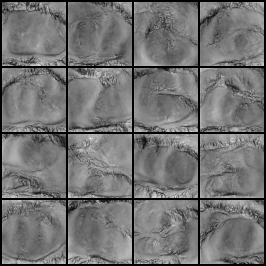

In [5]:

import torch
import json
from pathlib import Path
from torchvision.utils import save_image

# --------------------------------------------------
# 1. Load the saved checkpoint
# --------------------------------------------------
CHECKPOINT_PATH = MODEL_DIR / "IITD_small_ddpm_latest.pth"
SAMPLE_PATH = SAMPLE_DIR / "IITD_DDPM_generated_16.png"
SAMPLE_METADATA_PATH = OUT_DIR / "IITD_DDPM_sample_metadata.json"

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False
)
model.load_state_dict(checkpoint["model"])
model.eval()

# --------------------------------------------------
# 2. DDPM reverse sampling
# --------------------------------------------------
@torch.no_grad()
def sample_ddpm(model, n_samples=16):
    model.eval()
    x = torch.randn(
        n_samples, 1, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE
    )

    for step in reversed(range(TIMESTEPS)):
        t = torch.full(
            (n_samples,), step, device=DEVICE, dtype=torch.long
        )

        # Keep sampling in float32 for numerical stability.
        predicted_noise = model(x.float(), t)

        alpha_t = alphas[step]
        alpha_bar_t = alpha_bars[step]
        beta_t = betas[step]

        x = (1.0 / torch.sqrt(alpha_t)) * (
            x - (beta_t / torch.sqrt(1.0 - alpha_bar_t))
            * predicted_noise
        )

        if step > 0:
            noise = torch.randn_like(x)
            x = x + torch.sqrt(beta_t) * noise

    return x.clamp(-1, 1)

generated = sample_ddpm(model, n_samples=16)
generated_01 = (generated + 1) / 2

save_image(generated_01, SAMPLE_PATH, nrow=4)

# --------------------------------------------------
# 3. Record sampling details
# --------------------------------------------------
sample_metadata = {
    "model": "IITD compact unconditional DDPM",
    "checkpoint_epoch": int(checkpoint["epoch"]),
    "number_of_images": 16,
    "native_resolution": f"{IMAGE_SIZE}x{IMAGE_SIZE}",
    "diffusion_timesteps": TIMESTEPS,
    "sample_grid": str(SAMPLE_PATH),
    "identity_conditioning": False,
    "identity_preservation_verified": False,
    "note": (
        "Exploratory samples. Visual quality and biometric utility "
        "require separate evaluation."
    )
}

with open(SAMPLE_METADATA_PATH, "w") as f:
    json.dump(sample_metadata, f, indent=2)

print("Checkpoint epoch:", checkpoint["epoch"])
print("Generated images:", len(generated))
print("Generated tensor:", tuple(generated.shape))
print("Sample grid:", SAMPLE_PATH)
print("Metadata:", SAMPLE_METADATA_PATH)

from IPython.display import display
display(__import__("PIL").Image.open(SAMPLE_PATH))


Real tensor: (1, 64, 64)
Generated tensor: (1, 64, 64)

Real image statistics:
Min: 0.0
Max: 0.8274509906768799
Mean: 0.4679926931858063
Std: 0.20347319543361664

Generated image statistics:
Min: 0.09009948372840881
Max: 0.8204159736633301
Mean: 0.48401886224746704
Std: 0.09192273765802383


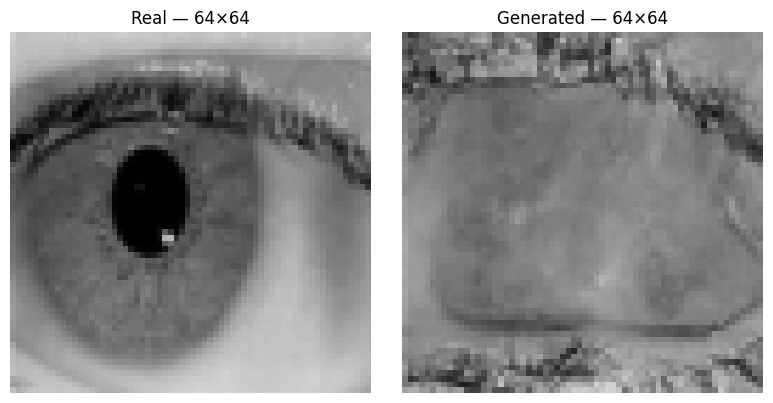


Checkpoint epoch: 100
Saved configuration: {'image_size': 64, 'timesteps': 100, 'batch_size': 32, 'learning_rate': 0.0002, 'seed': 42}

Forward schedule:
Beta start: 9.999999747378752e-05
Beta end: 0.019999999552965164
Final cumulative alpha: 0.36356320977211

All generated values finite: True
Generated tensor range: -1.0 0.8452549576759338

Diagnosis cell complete. No training performed.


In [6]:

import torch
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

# --------------------------------------------------
# 1. Compare real and generated images at 64x64
# --------------------------------------------------
real_path = manifest_df.iloc[0]["local_path"]
with Image.open(real_path) as im:
    real_img = transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor()
    ])(im.convert("L"))

fake_img = generated_01[0].detach().cpu()

print("Real tensor:", tuple(real_img.shape))
print("Generated tensor:", tuple(fake_img.shape))
print("\nReal image statistics:")
print("Min:", real_img.min().item())
print("Max:", real_img.max().item())
print("Mean:", real_img.mean().item())
print("Std:", real_img.std().item())

print("\nGenerated image statistics:")
print("Min:", fake_img.min().item())
print("Max:", fake_img.max().item())
print("Mean:", fake_img.mean().item())
print("Std:", fake_img.std().item())

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(real_img.squeeze(), cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Real — 64×64")
axes[0].axis("off")

axes[1].imshow(fake_img.squeeze(), cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Generated — 64×64")
axes[1].axis("off")

plt.tight_layout()
plt.show()

# --------------------------------------------------
# 2. Inspect the trained schedule and checkpoint
# --------------------------------------------------
checkpoint_path = MODEL_DIR / "IITD_small_ddpm_latest.pth"
ckpt = torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=False
)

print("\nCheckpoint epoch:", ckpt["epoch"])
print("Saved configuration:", ckpt.get("config"))

print("\nForward schedule:")
print("Beta start:", betas[0].item())
print("Beta end:", betas[-1].item())
print("Final cumulative alpha:", alpha_bars[-1].item())

# --------------------------------------------------
# 3. Check whether the generated tensor is finite
# --------------------------------------------------
print("\nAll generated values finite:", torch.isfinite(generated).all().item())
print("Generated tensor range:", generated.min().item(), generated.max().item())

print("\nDiagnosis cell complete. No training performed.")


Original terminal alpha-bar: 0.36356320977211
Cosine terminal alpha-bar: 2.4285395738843363e-07

Final diagnostic sample grid:


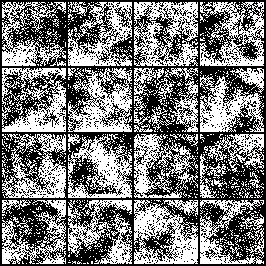

Saved: /content/drive5/MyDrive/Ocular_Project/results/IITD/notebook07_diffusion/final_sampling_attempt/IITD_DDPM_cosine_diagnostic.png
Metadata: /content/drive5/MyDrive/Ocular_Project/results/IITD/notebook07_diffusion/final_sampling_attempt/IITD_DDPM_cosine_diagnostic.json


In [7]:

import torch
import math
import json
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from torchvision.utils import save_image
from IPython.display import display
from PIL import Image

# --------------------------------------------------
# 1. Preserve the original sampling results
# --------------------------------------------------
FINAL_DIR = OUT_DIR / "final_sampling_attempt"
FINAL_DIR.mkdir(parents=True, exist_ok=True)

FINAL_GRID = FINAL_DIR / "IITD_DDPM_cosine_diagnostic.png"
FINAL_METADATA = FINAL_DIR / "IITD_DDPM_cosine_diagnostic.json"

# Reload the original trained checkpoint
ckpt = torch.load(
    MODEL_DIR / "IITD_small_ddpm_latest.pth",
    map_location=DEVICE,
    weights_only=False
)
model.load_state_dict(ckpt["model"])
model.eval()

# --------------------------------------------------
# 2. Construct cosine diagnostic schedule
# --------------------------------------------------
T = TIMESTEPS
steps = torch.arange(T + 1, device=DEVICE, dtype=torch.float64)

s = 0.008
f = torch.cos(
    ((steps / T + s) / (1 + s)) * math.pi / 2
) ** 2
alpha_bar_cos = (f / f[0]).clamp(1e-8, 1.0)

betas_cos = 1 - (
    alpha_bar_cos[1:] / alpha_bar_cos[:-1]
)
betas_cos = betas_cos.clamp(1e-5, 0.999).float()

alphas_cos = 1 - betas_cos
alpha_bars_cos = torch.cumprod(alphas_cos, dim=0)

print("Original terminal alpha-bar:", alpha_bars[-1].item())
print("Cosine terminal alpha-bar:", alpha_bars_cos[-1].item())

# --------------------------------------------------
# 3. Final diagnostic reverse sampler
# --------------------------------------------------
@torch.no_grad()
def sample_cosine_diagnostic(n=16):
    x = torch.randn(n, 1, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE)

    for t_idx in reversed(range(T)):
        t = torch.full((n,), t_idx, device=DEVICE, dtype=torch.long)

        # Use the cosine schedule for this diagnostic only.
        eps = model(x.float(), t)

        beta_t = betas_cos[t_idx]
        alpha_t = alphas_cos[t_idx]
        alpha_bar_t = alpha_bars_cos[t_idx]

        x = (x - beta_t / torch.sqrt(1 - alpha_bar_t) * eps) \
            / torch.sqrt(alpha_t)

        if t_idx > 0:
            alpha_bar_prev = alpha_bars_cos[t_idx - 1]
            posterior_variance = (
                beta_t * (1 - alpha_bar_prev) / (1 - alpha_bar_t)
            ).clamp(min=1e-20)

            x = x + torch.sqrt(posterior_variance) * torch.randn_like(x)

    return x.clamp(-1, 1)

final_samples = sample_cosine_diagnostic(16)
final_samples_01 = (final_samples + 1) / 2

save_image(final_samples_01, FINAL_GRID, nrow=4)

metadata = {
    "model_checkpoint_epoch": int(ckpt["epoch"]),
    "sampling_schedule": "cosine diagnostic",
    "training_schedule": "linear",
    "number_of_samples": 16,
    "image_size": IMAGE_SIZE,
    "retrained": False,
    "identity_conditioning": False,
    "identity_preservation_verified": False,
    "interpretation": (
        "Diagnostic only: sampling schedule differs from training schedule. "
        "Do not treat this as a controlled quality comparison."
    )
}

with open(FINAL_METADATA, "w") as f:
    json.dump(metadata, f, indent=2)

print("\nFinal diagnostic sample grid:")
display(Image.open(FINAL_GRID))
print("Saved:", FINAL_GRID)
print("Metadata:", FINAL_METADATA)


# Conclusion — Diffusion Model Training

A compact Denoising Diffusion Probabilistic Model (DDPM) was implemented and trained on the IIT Delhi ocular dataset using the 1,526-image training split. The model operated on 64×64 grayscale images and used a U-Net with approximately 779,000 trainable parameters.

## Training Results

- Training epochs completed: 100
- Batch size: 32
- Diffusion timesteps: 100
- Final recorded training noise-prediction loss: approximately 0.09909
- Training duration: approximately 5.36 minutes
- GPU: NVIDIA Tesla T4

The training loss generally decreased over the training run, indicating improvement in the model's noise-prediction objective. However, the generated samples did not show sufficiently clear ocular structures for reliable biometric augmentation.

## Sampling Diagnostics

The initial reverse-diffusion implementation used a linear noise schedule. Visual inspection showed blurry images without clearly recognizable iris and pupil structures. The original schedule's final cumulative alpha was approximately 0.3636, indicating that the terminal forward step retained a substantial amount of signal.

A separate diagnostic experiment used a cosine schedule during sampling without retraining the model. The resulting images were predominantly noisy. Because the model had been trained with a different schedule, this experiment was not a controlled evaluation of cosine-schedule training.

## Limitations

1. Training resolution was limited to 64×64, reducing the fine iris details available for learning.
2. The model was unconditional and did not generate verified identity-specific samples.
3. Visual quality was insufficient to establish the suitability of the generated images for biometric augmentation.
4. Training noise-prediction loss alone does not establish image realism, identity preservation, or downstream recognition improvement.
5. The alternative sampling schedule was a diagnostic experiment and should not be interpreted as evidence of a successfully trained cosine-schedule DDPM.

## Conclusion

The compact DDPM training pipeline and checkpoint-saving workflow were implemented successfully, but the generated samples did not meet the desired visual quality for ocular-image augmentation. The model is therefore retained as an exploratory baseline rather than a validated synthetic-image generator.

Further training and tuning were not pursued in this experiment because of the project time budget. Future work should investigate schedule-consistent sampling, higher-resolution training, and dedicated image-quality and identity-preservation evaluation.

The diffusion model's effectiveness for biometric augmentation remains unproven and must be evaluated against the other augmentation methods in subsequent experiments.